In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import scanpy as sc
from scipy import stats
import matplotlib.gridspec as gridspec


 

In [2]:
import matplotlib

sc.settings.figdir = "supp"
sc.settings.set_figure_params(dpi=50, dpi_save=300, facecolor="white", frameon=False, figsize=(18,18),
                              vector_friendly=True
                             )
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

In [3]:
FILE_NAME = "adata_combined_new.h5ad.final.filtered"
PATH2=f'/nfs/team298/ls34/adult_skin/final_adatas/{FILE_NAME}'
adata=sc.read_h5ad(PATH2)
adata_5k=adata[adata.obs["tech"]=="xenium"].copy()
adata=adata[adata.obs["tech"]!="xenium"]


def remove_markers(LIST):
    try: 
        LIST = {key: [gene for gene in genes if gene in adata_5k.var_names] 
                           for key, genes in LIST.items()}
    except: 
        LIST =[gene for gene in LIST if gene in adata_5k.var_names]
    return LIST

 



In [4]:
sc.pp.normalize_total(adata_5k, target_sum=1e4)
sc.pp.log1p(adata_5k)

In [5]:
# sc.pp.normalize_total(adata, target_sum=1e4)
# sc.pp.log1p(adata)

In [6]:
# adata_i=adata_5k[adata_5k.obs["niche19"]=="Tzone-like"]
# adata_i=adata_i[adata_i.obs["Site_status"]=="Lesional"]


# counts = adata_i.obs["info_id6"].value_counts()
# valid_donors = counts[counts >= 100].index
# adata_i = adata_i[adata_i.obs["info_id6"].isin(valid_donors)].copy()



In [7]:
adata_i = adata_5k[
    (adata_5k.obs["Site_status"].isin(["Lesional", "3D_Lesional_baseline"])) &
    (adata_5k.obs["niche19"] == "Tzone-like")
]


In [8]:
adata_5k.obs["Site_status"].value_counts()

Site_status
Lesional                            205785
Non-lesional                        192952
3D_Week12                           180311
3D_Lesional_baseline                153479
Week 12                             149280
Psoriasis_replicate_non-lesional     76048
Remission_longterm (past)            75050
Remission_longterm (never)           74463
Week 8 Psoriasis                     72094
Psoriasis_replicate_Lesional         60647
Healthy                              59315
Psoriasis_replicate_PostRx           49385
Day 14_HF                            30438
Relapse                              25836
Remission_longterm (week 8)          23372
Name: count, dtype: int64

In [9]:
# adata_5k_ii=
                     


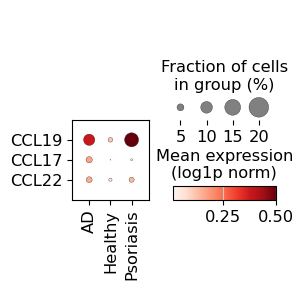

In [10]:
"""
NEED TO UPDATE IN PAPER
"""
sc.pl.dotplot(adata_5k[(adata_5k.obs["Site_status"]=="Healthy")|
                     (adata_5k.obs["Site_status"]=="Lesional")], 
             ["CCL19", "CCL17", "CCL22"],
              groupby="disease_overall",
              dendrogram=False, 
                #standard_scale="var",
              dot_max=0.2,
              vmax=.5,
              colorbar_title="Mean expression\n(log1p norm)",
              swap_axes=True,
             #categories_order = [x for x in ORDER_T if x in adata_ii.obs[CATEGORY].unique()],
             save="e6f_ccl_expression_scrna.pdf"
             )

In [11]:
# stop

In [32]:
import re
adata_i.obs["patient"] = (adata_i.obs["info_id6"].astype(str)
                          .str.extract(r'(BK\d+|CE\d+)', expand=False))
print(adata_i.obs.groupby("disease_overall", observed=True)["patient"].nunique())
print(adata_i.obs.groupby("disease_overall", observed=True)["patient"]
      .apply(lambda s: sorted(s.unique())))


disease_overall
AD           8
Psoriasis    4
Name: patient, dtype: int64
disease_overall
AD           [BK18, BK21, BK22, BK23, BK24, BK25, BK30, BK39]
Psoriasis                                [CE3, CE4, CE5, CE6]
Name: patient, dtype: object


disease_overall
AD           19
Psoriasis    19
Name: donor, dtype: int64


/tmp/ipykernel_4131749/964824699.py:18: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(


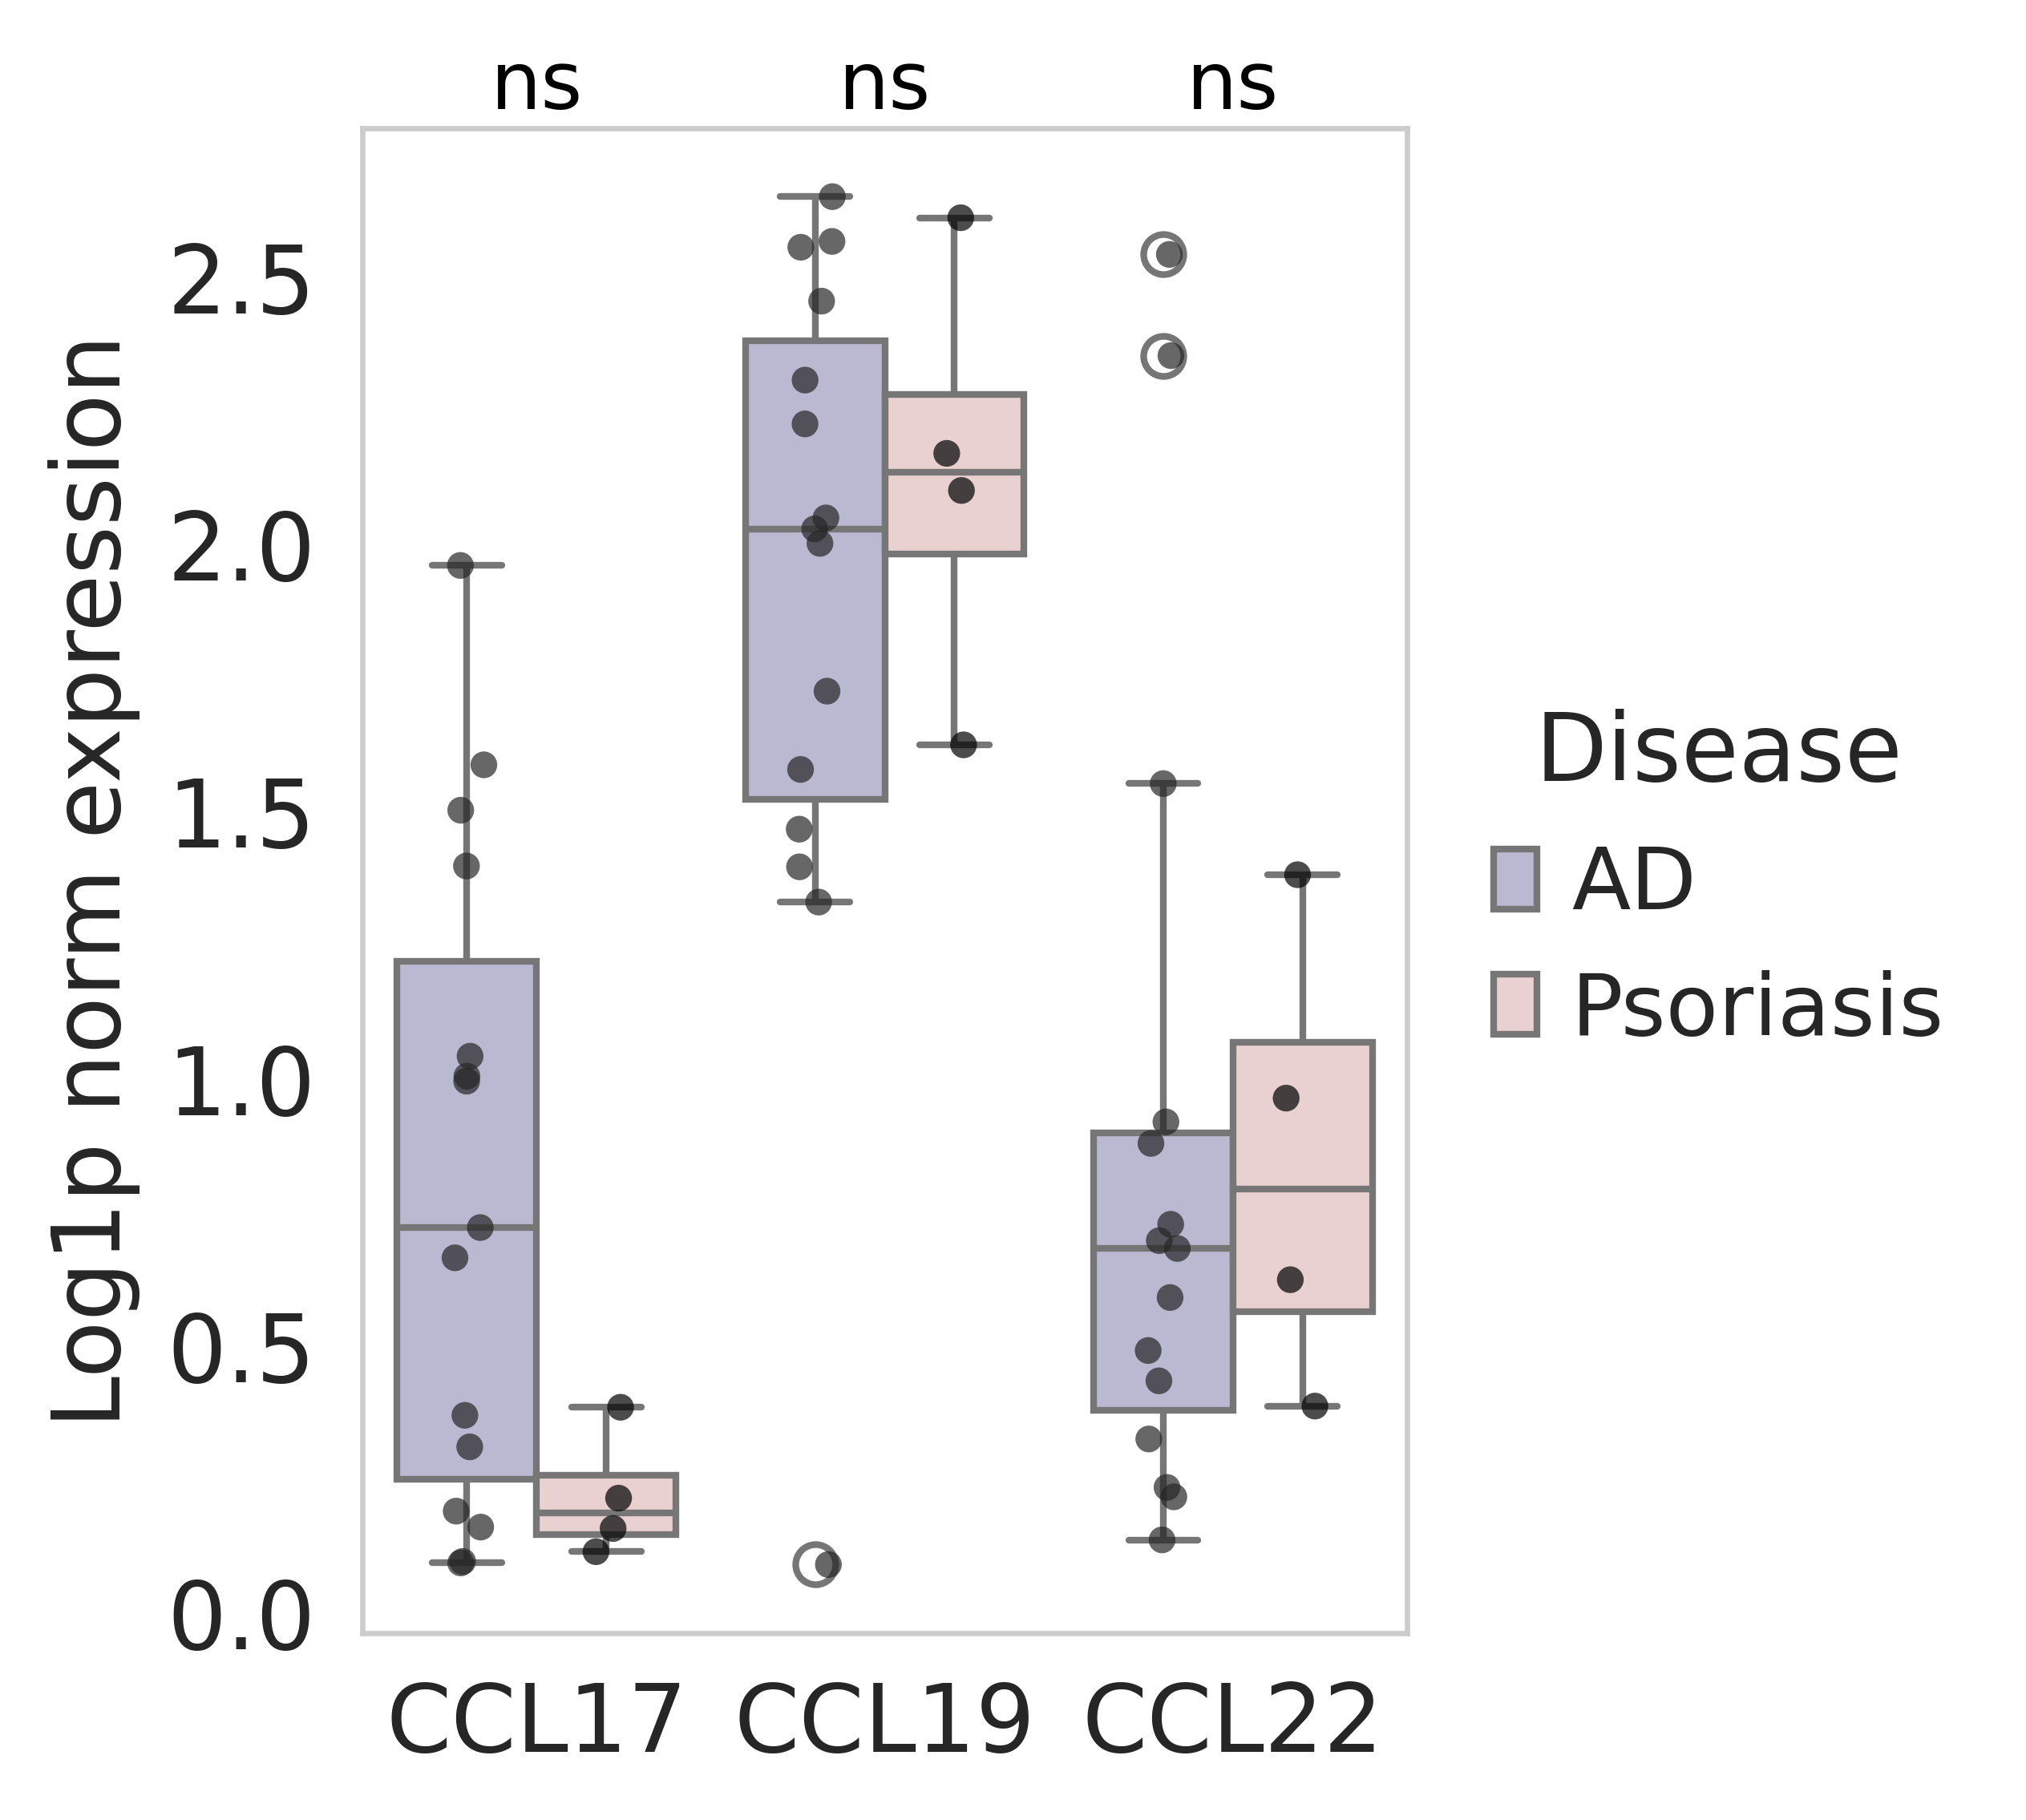

In [17]:
# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(4.5, 4), dpi=300)
sns.set_style("whitegrid", {'axes.grid': False})
custom_palette = {"AD": "#b8b4d5", "Psoriasis": "#eccdcc"}

#print(df_donors.groupby(["gene", "disease_overall"], observed=True).size().unstack())
print(df_donors.groupby("disease_overall", observed=True)["donor"].nunique())
ax = sns.boxplot(
    data=df_donors,
    x="gene",
    y="expression",
    hue="disease_overall",
    palette=custom_palette
)

sns.stripplot(
    data=df_donors,
    x="gene",
    y="expression",
    hue="disease_overall",
    dodge=True,
    size=4,
    color="k",
    alpha=0.7,
    ax=ax
)

# ----------------------------
# Legend outside plot (to the right)
# ----------------------------
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[:2],
    labels[:2],
    title="Disease",
    frameon=False,
    bbox_to_anchor=(1.05, 0.5),   # move legend to the right
    loc="center left",
    borderaxespad=0
)

# ----------------------------
# Axis labels, title, annotations
# ----------------------------
ax.set_xlabel("")
ax.set_ylabel("Log1p norm expression")
ax.set_title("")

y_max = df_donors["expression"].max()
for i, row in results_df.iterrows():
    ax.text(i, y_max * 1.05, row["star"], ha="center", va="bottom", fontsize=12, color="black")

plt.tight_layout()
plt.savefig("supp/supp_ccl17_chemokines.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
print(adata.obs["disease_overall"].isna().sum(), "of", adata.n_obs, "are NaN")
print(adata.obs["disease_overall"].dtype)
print(adata.obs["disease_overall"].unique()[:10])



1730938 of 1730938 are NaN
category
[NaN]
Categories (0, object): []


In [29]:
adata[adata.obs["Patient_status"]=="Psoriasis"].obs.info_id6.value_counts()

Series([], Name: count, dtype: int64)

In [27]:
print(adata.shape)
print("disease_overall" in adata.obs.columns)
print(adata.obs.columns.tolist()[:30])



(1730938, 4993)
True
['sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'n_genes', 'dataset_id', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'QC_hi', 'QC_mid', 'lvl5_annotation', 'Mapping_status', 'scanvi_predictions', 'lvl5_annotation_new', 'lvl5_annotation_new2', 'lvl5_annotation_new3', 'lvl5_annotation_new_archive', 'lvl5_annotation_new_preoprhan']
